#Best Selling Product and Category

In [346]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
cols_needed = ['prod_name', 'product_group_name', 'price']

path = '../data/processed/merged_cleaned_2019.csv'

df = pd.read_csv(path, usecols=cols_needed)

In [348]:
df.shape

(16396930, 3)

In [349]:

df.head()

,prod_name,product_group_name,price
0,Bilbo denim,Garment Upper body,0.045763
1,Curvy Jeggings HW Ankle,Garment Lower body,0.033881
2,Empire HW wide leg denim,Garment Lower body,0.061000
3,Shark Boxy Sweater,Garment Upper body,0.015237
4,Alison shirt dress w,Garment Full body,0.033881


In [350]:
df['price'].describe()

count    1.639693e+07
mean     2.778599e-02
std      1.937508e-02
min      1.694915e-05
25%      1.523729e-02
50%      2.540678e-02
75%      3.388136e-02
max      5.067797e-01
Name: price, dtype: float64

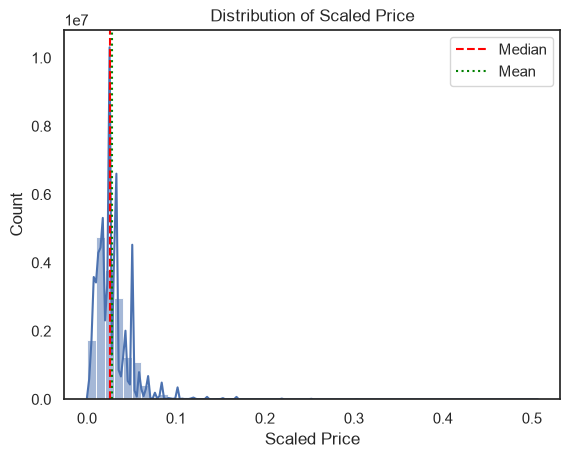

In [ ]:
sns.histplot(df['price'], bins=50, kde=True)

plt.axvline(df['price'].median(), color='red', linestyle='--', label='Median')

plt.axvline(df['price'].mean(), color='green', linestyle=':', label='Mean')

plt.title('Distribution of Scaled Price')
plt.xlabel('Scaled Price')

plt.legend()

plt.show()


In [352]:
category_counts = df['product_group_name'].value_counts()

print(category_counts)


product_group_name
Garment Upper body       6504648
Garment Lower body       3640857
Garment Full body        1834274
Swimwear                 1395575
Underwear                1265479
Accessories               816234
Shoes                     399769
Socks & Tights            335178
Nightwear                 175883
Unknown                    23081
Bags                        3056
Items                       1684
Furniture                    456
Cosmetic                     418
Underwear/nightwear          245
Garment and Shoe care         64
Interior textile              29
Name: count, dtype: int64


In [353]:
category_revenue = df.groupby('product_group_name')['price'].sum()
print(category_revenue)

product_group_name
Accessories               12872.000237
Bags                        103.919695
Cosmetic                      2.328915
Furniture                     3.514305
Garment Full body         67792.429237
Garment Lower body       118622.755678
Garment Upper body       173904.623475
Garment and Shoe care         0.689492
Interior textile              0.312000
Items                        19.891441
Nightwear                  4385.852288
Shoes                     15630.562237
Socks & Tights             3837.860949
Swimwear                  31619.710695
Underwear                 26246.506542
Underwear/nightwear           6.888864
Unknown                     555.031915
Name: price, dtype: float64


In [354]:
category_summary = pd.DataFrame({
  'purchases': category_counts,
  'scaled_revenue': category_revenue
}).sort_values('scaled_revenue', ascending=False)

print(category_summary)

                       purchases  scaled_revenue
product_group_name                              
Garment Upper body       6504648   173904.623475
Garment Lower body       3640857   118622.755678
Garment Full body        1834274    67792.429237
Swimwear                 1395575    31619.710695
Underwear                1265479    26246.506542
Shoes                     399769    15630.562237
Accessories               816234    12872.000237
Nightwear                 175883     4385.852288
Socks & Tights            335178     3837.860949
Unknown                    23081      555.031915
Bags                        3056      103.919695
Items                       1684       19.891441
Underwear/nightwear          245        6.888864
Furniture                    456        3.514305
Cosmetic                     418        2.328915
Garment and Shoe care         64        0.689492
Interior textile              29        0.312000


In [355]:
category_price_stats = df.groupby('product_group_name')['price'].describe().reindex(category_summary.index)
category_price_stats

,count,mean,std,min,25%,50%,75%,max
product_group_name,,,,,,,,
Garment Upper body,6504648.0,0.026735,0.021470,0.000017,0.013542,0.022017,0.033881,0.506780
Garment Lower body,3640857.0,0.032581,0.017012,0.000186,0.021593,0.032186,0.042356,0.422034
Garment Full body,1834274.0,0.036959,0.021203,0.000407,0.024797,0.033881,0.049169,0.506780
Swimwear,1395575.0,0.022657,0.010552,0.000119,0.016932,0.022017,0.025407,0.084729
Underwear,1265479.0,0.020740,0.009569,0.000051,0.013542,0.018712,0.025407,0.118627
Shoes,399769.0,0.039099,0.025727,0.000203,0.022017,0.033881,0.050831,0.337288
Accessories,816234.0,0.015770,0.011458,0.000051,0.008458,0.013542,0.018627,0.337288
Nightwear,175883.0,0.024936,0.010111,0.000847,0.016932,0.025407,0.033881,0.080881
Socks & Tights,335178.0,0.011450,0.005061,0.000119,0.008119,0.012186,0.013542,0.050831


In [356]:
product_revenue = df.groupby('prod_name')['price'].sum().sort_values(ascending=False)
print(product_revenue.head()) 

prod_name
Jade HW Skinny Denim TRS      3070.508627
Luna skinny RW                2122.424593
Shaping Skinny H.W            1614.769203
Push Up Jegging L.W           1163.673915
Embrace S.Skinny Ankle H.W    1147.140847
Name: price, dtype: float64


In [357]:
top_products = product_revenue.head(20)

In [358]:
product_category_revenue = df.groupby(['prod_name', 'product_group_name'])['price'].sum().sort_values(ascending=False)

print(product_category_revenue)

prod_name                   product_group_name
Jade HW Skinny Denim TRS    Garment Lower body    3070.508627
Luna skinny RW              Garment Lower body    2122.424593
Shaping Skinny H.W          Garment Lower body    1614.769203
Push Up Jegging L.W         Garment Lower body    1163.673915
Embrace S.Skinny Ankle H.W  Garment Lower body    1147.140847
                                                     ...     
Flirty New years Aliceband  Accessories              0.000780
Erasers                     Accessories              0.000593
Elin thin hair elastic      Accessories              0.000441
H-clip 2pk watermelon       Accessories              0.000441
Classic Wayne sunglasses    Accessories              0.000424
Name: price, Length: 32875, dtype: float64


In [359]:
print(category_summary.tail(3))

                       purchases  scaled_revenue
product_group_name                              
Cosmetic                     418        2.328915
Garment and Shoe care         64        0.689492
Interior textile              29        0.312000


In [ ]:
product_counts = df['prod_name'].value_counts()

sold_once = (product_counts == 1).sum()

print(f"{sold_once} of {len(product_counts)} products sold once ({sold_once / len(product_counts):.1%})")

1892 of 32667 products sold once (5.8%)


In [ ]:
sold_once_names = product_counts[product_counts == 1].index

sold_once_products = df[df['prod_name'].isin(sold_once_names)][['prod_name', 'product_group_name', 'price']]

sold_once_products.sample(10, random_state=42)




,prod_name,product_group_name,price
7507401,Bosse 5p boy,Socks & Tights,0.005407
5101240,Ian seamless tee,Garment Upper body,0.011847
12516581,Leonora earrings,Accessories,0.011000
14016880,RELAXED BLUEBLK 89,Garment Lower body,0.020339
4776620,Cloud scallop shorts,Garment Lower body,0.010169
13211086,Rollerneck Etienne,Garment Upper body,0.033898
8215092,Jesper Trouser,Garment Lower body,0.010153
11784438,Tyson highshaft,Shoes,0.101678
5106437,Elvis jumper,Garment Upper body,0.036593
14366166,Sima leather sandal SG,Shoes,0.031407


In [ ]:
revenue_share = (category_summary['scaled_revenue'] / category_summary['scaled_revenue'].sum())

print(revenue_share.map('{:.2%}'.format))

product_group_name
Garment Upper body       38.17%
Garment Lower body       26.04%
Garment Full body        14.88%
Swimwear                  6.94%
Underwear                 5.76%
Shoes                     3.43%
Accessories               2.83%
Nightwear                 0.96%
Socks & Tights            0.84%
Unknown                   0.12%
Bags                      0.02%
Items                     0.00%
Underwear/nightwear       0.00%
Furniture                 0.00%
Cosmetic                  0.00%
Garment and Shoe care     0.00%
Interior textile          0.00%
Name: scaled_revenue, dtype: str


In [363]:
top_five_share = revenue_share.head(5)


In [364]:
product_category_revenue.head(20).index.get_level_values('product_group_name').value_counts()

product_group_name
Garment Lower body    12
Garment Upper body     4
Swimwear               4
Name: count, dtype: int64

In [365]:
f"{revenue_share.tail(3).sum():.4%}"

'0.0007%'

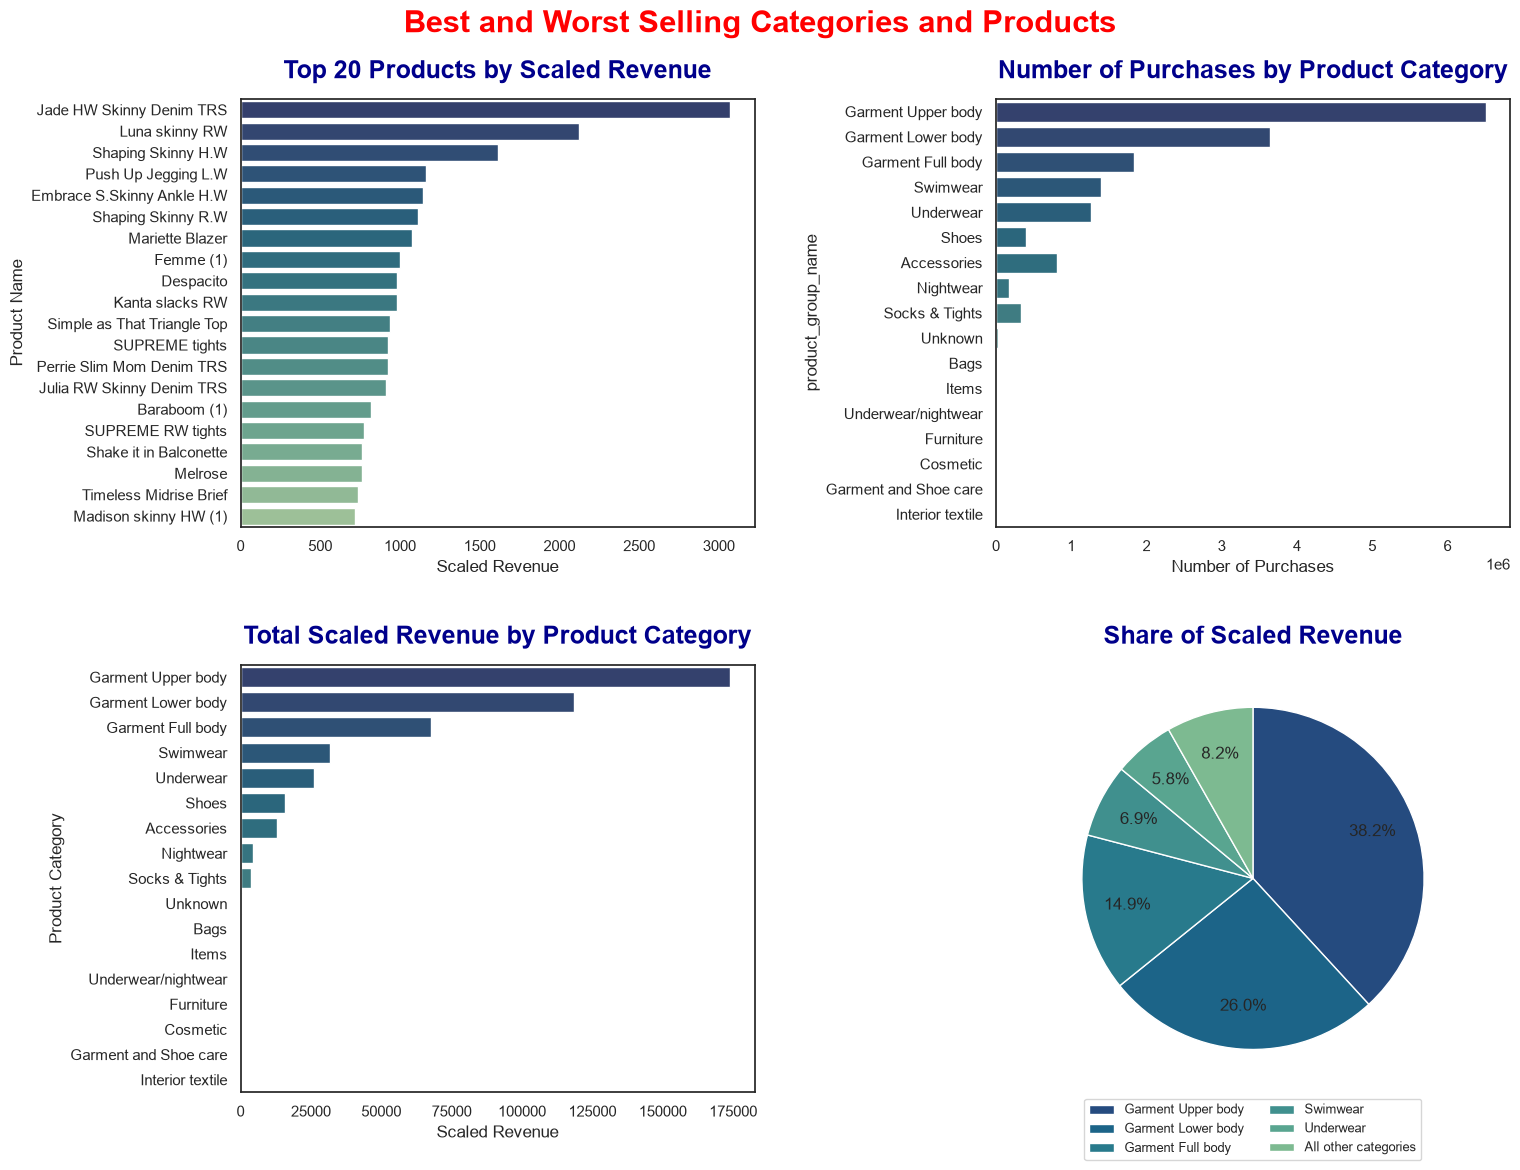

In [ ]:
sns.set_style('white')

figure, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, palette='crest_r', legend=False, ax=axes[0, 0])

axes[0, 0].set_title('Top 20 Products by Scaled Revenue',pad=15,fontsize=18,fontweight='bold',color='darkblue')

axes[0, 0].set_xlabel('Scaled Revenue')
axes[0, 0].set_ylabel('Product Name')

counts_in_revenue_order = category_counts.reindex(category_summary.index)

sns.barplot(
  x=counts_in_revenue_order.values, y=counts_in_revenue_order.index, hue=counts_in_revenue_order.index, palette='crest_r', 
  legend=False, ax=axes[0, 1])

axes[0, 1].set_title('Number of Purchases by Product Category',pad=15,fontsize=18,fontweight='bold',color='darkblue')


axes[0, 1].set_xlabel('Number of Purchases')

pie_data = pd.concat([top_five_share, pd.Series({'All other categories': revenue_share.iloc[5:].sum()})])

wedges, texts, autotexts = axes[1, 1].pie(
    pie_data, autopct='%1.1f%%', startangle=90, counterclock=False, pctdistance=0.75,
    colors=sns.color_palette('crest_r', len(pie_data))
)
axes[1, 1].legend(wedges, pie_data.index, loc='upper center', bbox_to_anchor=(0.5, 0), ncol=2, fontsize=9)
axes[1, 1].set_title('Share of Scaled Revenue',pad=15,fontsize=18,fontweight='bold',color='darkblue')

sns.barplot(x=category_summary['scaled_revenue'], y=category_summary.index, hue=category_summary.index, palette='crest_r', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Total Scaled Revenue by Product Category',pad=15,fontsize=18,fontweight='bold',color='darkblue')
axes[1, 0].set_xlabel('Scaled Revenue')
axes[1, 0].set_ylabel('Product Category')

plt.tight_layout(pad=3)

plt.suptitle('Best and Worst Selling Categories and Products', fontsize=22, fontweight='bold', color='red', y=1.0)

figure.savefig('../reports/best_selling_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

## Findings

Prices in the 2019 data are right-skewed. Most purchases are low-priced, and a small number of expensive ones pull the mean above the median.

Garment Upper body is the largest category, with 6.5M purchases and 38.2% of total scaled revenue. Its average price is 0.027, below Garment Full body at 0.037 and Bags at 0.034, so its lead is consistent with volume and not price.

Accessories has more purchases than Shoes, 816K against 400K. Though Shoes earns more scaled revenue, 15.6K against 12.9K. Shoes have the higher typical price with a median of 0.034 against 0.014 which is consistent with that.

12 of the top 20 products by scaled revenue are Garment Lower body. Garment Upper body and Swimwear have 4 each.

Cosmetic, Garment and Shoe care, and Interior textile earn the least scaled revenue, under 0.01% of the total together. They are small side categories in this data.

1,892 of 32,667 products, or 5.8%, sold exactly once, so I did not rank the worst-selling products.